In [3]:
import numpy as np
from langchain_ollama import ChatOllama
from rag_flow import RAGFlow
import pandas as pd
from time import perf_counter
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import requests

from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

/Users/vilya/Desktop/capstone_project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-09 18:49:41,747 | INFO | No device provided, using mps
2026-10-09 18:49:41,893 | INFO | HTTP Request: HEAD https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 404 Not Found"
2026-10-09 18:49:41,893 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-09 18:49:41,895 | INFO | No modules.json found for cross-encoder/ms-marco-MiniLM-L6-v2, initializing a new CrossEncoder model.
2026-10-09 18:49:41,990 | INFO | HTTP Request: GET https://huggingface.co/api/models/cross-encoder/ms-marco-MiniLM-L6-v2 "HTTP/1.1 200 OK"
2026-10-09 18:49:42,087 | INFO | HTTP Request: GE

This file focuses on classifier llm evaluation. I am using langchain ollama library to simplify usage of two different models. I will compare accuracy, precision and recall, as well as running time between qwen3:8b and llama3.2:3b. I use synthetically created by ChatGPT balanced test data set consisting of 300 questions for evalution.

In [4]:
response = requests.get("http://localhost:11434/api/tags")
models = response.json()["models"]

for model in models:
    print(f"{model['name']}: {model['size'] / 1024**3:.2f} GB")

qwen3:8b: 4.87 GB
llama3.2:3b: 1.88 GB
nomic-embed-text:latest: 0.26 GB
gpt-oss:20b: 12.85 GB


In [5]:
evaluation_df = pd.DataFrame({
    "qwen" : {
        "accuracy": None,
        "precision": None,
        "recall": None,
        "mean_latency": None
    },
    "llama": {
        "accuracy": None,
        "precision": None,
        "recall": None,
        "mean_latency": None
    }
})

In [6]:
df = pd.read_csv("test_data/arxiv_classifier_300_questions.csv")
print(df["label"].value_counts())
df.head(3)

label
arxiv        150
not_valid    150
Name: count, dtype: int64


,question,label,source,difficulty,topic
0,What are the main limitations of economic grow...,arxiv,synthetic,easy,economics
1,What are some practical tips for a neighborhoo...,not_valid,synthetic,easy,everyday
2,What are the main limitations of operating sys...,arxiv,synthetic,easy,computer science


In [7]:
qwen = ChatOllama(
    model="qwen3:8b",
    base_url="http://localhost:11434"
)

llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434"
)
classifier_model =

In [8]:
params = {
    "model": qwen,
    "web_query_max_new_t": 50,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "top_k_chunks": 5,
    "answer_max_new_t": 500,
    "classifier_max_new_t": 10,
}


KeyError: 'classifier'

In [7]:
qwen_rag = RAGFlow(params)
qwen_results = []
qwen_latencies = []
for q in df["question"]:
    start = perf_counter()
    qwen_results.append(qwen_rag._classify_promt(q))
    latency = perf_counter() - start
    qwen_latencies.append(latency)
df["qwen_prediction"] = qwen_results
df["qwen_latency"] = qwen_latencies

2026-10-09 13:41:22,305 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:25,959 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:31,409 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:34,571 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:39,694 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:42,980 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:48,044 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:51,992 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:54,960 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 13:41:57,999 | INFO | HTTP Request: POST http://localhost:11434/api/cha

In [8]:
params = {
    "model": llama,
    "web_query_max_new_t": 50,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "top_k_chunks": 5,
    "answer_max_new_t": 500,
    "classifier_max_new_t": 10
}

In [9]:
llama_rag = RAGFlow(params)
llama_results = []
llama_latencies = []
for q in df["question"]:
    start = perf_counter()
    llama_results.append(llama_rag._classify_promt(q))
    latency = perf_counter() - start
    llama_latencies.append(latency)
df["llama_prediction"] = llama_results
df["llama_latency"] = llama_latencies

2026-10-09 14:46:42,466 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,537 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,604 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,672 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,742 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,810 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:42,877 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:43,046 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:43,115 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 14:46:43,183 | INFO | HTTP Request: POST http://localhost:11434/api/cha

In [41]:
y_true = df["label"]
y_q_pred = df["qwen_prediction"]
y_l_pred = df["llama_prediction"]

evaluation_df.loc["accuracy", "qwen"] = accuracy_score(y_true, y_q_pred)
evaluation_df.loc["accuracy", "llama"] = accuracy_score(y_true, y_l_pred)

evaluation_df.loc["precision", "qwen"] = precision_score(y_true, y_q_pred, pos_label="arxiv",)
evaluation_df.loc["precision", "llama"] = precision_score(y_true, y_l_pred, pos_label="arxiv",)

evaluation_df.loc["recall", "qwen"] = recall_score(y_true, y_q_pred, pos_label="arxiv",)
evaluation_df.loc["recall", "llama"] = recall_score(y_true, y_l_pred, pos_label="arxiv",)

evaluation_df.loc["mean_latency", "qwen"] = np.mean(df["qwen_latency"])
evaluation_df.loc["mean_latency", "llama"] = np.mean(df["llama_latency"])
evaluation_df

,qwen,llama
accuracy,0.983333,0.67
precision,0.993197,1.0
recall,0.973333,0.34
mean_latency,5.444929,0.077263


```
	qwen	llama
accuracy	0.983333	0.67
precision	0.993197	1.0
recall	0.973333	0.34
mean_latency	5.444929	0.077263
```

From the dataframe above, we see that qwen has much better scores on all metrics than llama. However, the light-weighted llama perfomred much faster. Llama model's accuracy is 67%, which mean 67% of the answers were correct. And recall - 34%, the recall score is a little too low, I would like to work on the prompt to improve it. Below, you can see some examples of false negatives, valid questions that llama refused to classify as arxive. All of them look valid, so the model has to be improved.


**_Conclusion_:** Llama model will be chosen for the classification task, but recall score has to be improved by prompt engineering, or parameter tuning.

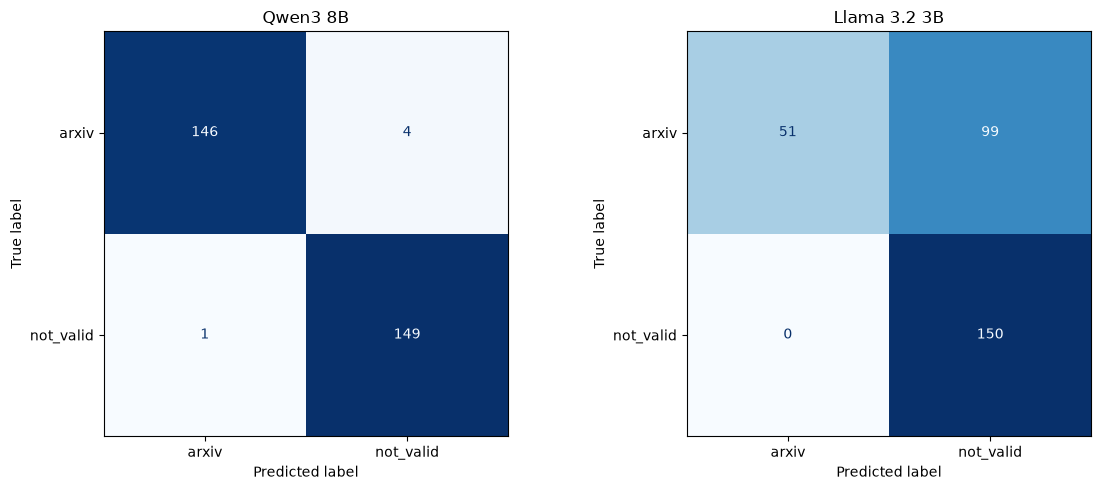

In [39]:
labels = ["arxiv", "not_valid"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model, predictions) in zip(
    axes,
    [("Qwen3 8B", y_q_pred), ("Llama 3.2 3B", y_l_pred)]
):
    cm = confusion_matrix(
        y_true,
        predictions,
        labels=labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(model)

plt.tight_layout()
plt.show()

In [53]:
pd.set_option("display.max_colwidth", None)
# False negatives by llama:
df[(df["llama_prediction"] == "not_valid") & (df["label"] == "arxiv")][["question", "topic", "difficulty"]]


,question,topic,difficulty
2,What are the main limitations of operating system scheduling?,computer science,easy
4,How can researchers evaluate SQL query optimization?,databases,easy
5,What is prompt engineering?,technical_applied,borderline
8,What are the main limitations of gradient descent optimization?,mathematics,easy
10,How does database indexing work?,databases,easy
...,...,...,...
288,How does Bayesian inference work?,statistics,easy
291,How can researchers evaluate software testing strategies?,software engineering,easy
295,How does numerical linear algebra work?,mathematics,easy
298,How does reinforcement learning work?,artificial intelligence,easy


In [4]:
# Added temperature=0 and few-shot examples to the system prompt.
new_llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0
)

params = {
    "model": new_llama,
    "web_query_max_new_t": 50,
    "titles_limit": 5,
    "top_k_titles": 5,
    "chunk_size": 200,
    "chunk_overlap_fraction": 0.2,
    "top_k_chunks": 5,
    "answer_max_new_t": 500,
    "classifier_max_new_t": 10
}

new_llama_rag = RAGFlow(params)

new_llama_results = []
new_llama_latencies = []

for q in df["question"]:
    start = perf_counter()

    prediction = new_llama_rag._classify_promt(q)

    latency = perf_counter() - start

    new_llama_results.append(prediction.strip().lower())
    new_llama_latencies.append(latency)

df["new_llama_prediction"] = new_llama_results
df["new_llama_latency"] = new_llama_latencies

2026-10-09 16:19:37,363 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,434 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,503 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,573 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,640 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,708 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,776 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,860 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:37,930 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-09 16:19:38,000 | INFO | HTTP Request: POST http://localhost:11434/api/cha

In [5]:
y_true = df["label"]
y_nl_pred = df["new_llama_prediction"]

evaluation_df.loc["accuracy", "new_llama"] = accuracy_score(y_true, y_nl_pred)
evaluation_df.loc["precision", "new_llama"] = precision_score(y_true, y_nl_pred, pos_label="arxiv")
evaluation_df.loc["recall", "new_llama"] = recall_score(y_true, y_nl_pred, pos_label="arxiv", zero_division=0)
evaluation_df.loc["mean_latency", "new_llama"] = np.mean(df["new_llama_latency"])
evaluation_df

,qwen,llama,new_llama
accuracy,None,None,0.896667
precision,None,None,0.991736
recall,None,None,0.800000
mean_latency,None,None,0.069331


In [7]:
df[(df["new_llama_prediction"] == "not_valid") & (df["label"] == "arxiv")][["question", "topic", "difficulty"]].head(5)

,question,topic,difficulty
4,How can researchers evaluate SQL query optimiz...,databases,easy
23,How do I install a Python package in a virtual...,technical_applied,borderline
26,How do I center a div using CSS?,technical_applied,borderline
40,What is a primary key in a database?,technical_applied,borderline
44,What is a confidence interval?,technical_applied,borderline


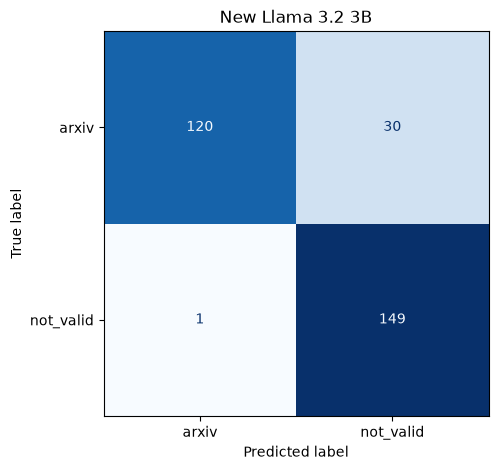

In [8]:
labels = ["arxiv", "not_valid"]
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(
    y_true,
    df["new_llama_prediction"],
    labels=labels
)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("New Llama 3.2 3B")
plt.show()


After experimenting with several versions of system prompt, I have managed to increase the recall score up to 80%.
```
accuracy	0.896667
precision	0.991736
recall	    0.800000
mean_latency 0.069331
```


